# Lab 5 — Motor Parameter Identification

**Course:** CS413 Robotics · **Robot:** TRIK, differential drive, RK370 DC motors · **Data recorded:** 2026-10-22

This notebook walks through the whole lab in order — the task, the model, the experiment on the robot, the data, the fitting, the simulation check and the conclusions. Every number and graph below is computed live from the 80 raw files the robot wrote (`motor_data/`).

**Contents**
1. The task
2. The motor model
3. The experiment on the robot
4. The raw data
5. Fitting the model to one run
6. Fitting all 80 runs
7. Steady-state speed vs voltage → `k_e`
8. The time constant `T_m` across PWM levels
9. Simulation check (`odeint`) against a measurement
10. How different are the two wheels? → odometry
11. Results and conclusions

## 1. The task

Identify the two parameters of each drive motor of our robot:

| Parameter | Meaning | Unit |
|---|---|---|
| `T_m` | electromechanical time constant — how fast the motor reaches its speed | s |
| `k_e` | back-EMF constant — how many volts one rad/s of speed "costs" | V·s/rad |

What the lab requires:
- run a **step-response experiment** on **both drive wheels**, for every PWM level from −100 % to +100 % in 5 % steps, with the battery voltage logged;
- fit the model offline and report `T_m` and `ω_ss` for every level, and `k_e` per wheel;
- **simulate** the identified motor and compare it with a measurement;
- discuss where the linear model fails, how much the wheels differ, and what that means for odometry next week.

These parameters are reused in Week 6 (localization) and Week 7 (go-to-goal).

## 2. The motor model

A DC motor with a light load behaves like a **first-order system** in angular velocity (the armature inductance is neglected because the electrical time constant is much shorter than the mechanical one):

$$T_m\,\frac{d\omega}{dt} + \omega = \frac{U}{k_e}, \qquad \frac{d\theta}{dt} = \omega$$

If we apply a voltage step $U$ at $t=0$ with the motor at rest, the solution is

$$\omega(t) = \omega_{ss}\left(1 - e^{-t/T_m}\right), \qquad \theta(t) = \omega_{ss}\left(t - T_m + T_m\,e^{-t/T_m}\right), \qquad \omega_{ss} = \frac{U}{k_e}$$

The robot's encoder measures the **angle** $\theta(t)$, so we fit the second formula:
- the **slope** of $\theta(t)$ once it becomes a straight line gives $\omega_{ss}$;
- **how long it takes to bend** into that line gives $T_m$;
- repeating for many voltages, the slope of $\omega_{ss}$ against $U$ gives $1/k_e$.

The TRIK sets PWM, not volts, so the voltage is estimated as $U = \frac{PWM}{100}\cdot U_{battery}$.

## 3. The experiment on the robot

**Setup:** the robot stands on a support with both drive wheels in the air (no load), battery charged (≈ 12.1 V).

**Program:** `motor_identification.qrs` (TRIK Studio, Python; the same code is in `motor_identification.py`). For wheel 1 (`M3`/`E3`) and then wheel 2 (`M4`/`E4`), for each of the 40 PWM levels it:

1. resets the encoder and waits 0.5 s with the motor off, reads the battery voltage;
2. applies the PWM step and records *(time stamp, encoder angle)* for 2 s **into a list in memory**;
3. reads the battery voltage again (under load), switches the motor off, and only **then** writes the file;
4. waits 1 s so the wheel stops before the next level.

The core of the program:

```python
def record_step(motor, encoder, power):
    encoder.reset()
    script.wait(SETTLE_MS)
    battery_rest = battery_volts()

    samples = []
    t0 = time.time()
    motor.setPower(power)                       # the step: t = 0
    while True:
        t = time.time() - t0
        if t > RUN_TIME:
            break
        samples.append((int(t * 1000), encoder.read()))
        script.wait(DT_MS)

    battery_load = battery_volts()
    motor.powerOff()
    return samples, battery_rest, battery_load
```

**Why it is written this way**
- *No file writing while sampling* — writing a file inside the loop makes the sampling period long and irregular (the course's reference data was sampled every 20–61 ms because of it). Here we got a steady ≈ 10 ms.
- *Real time stamps* — every sample has its own time, so small delays in the loop do not distort the time axis.
- *Battery voltage for every step* — needed to convert PWM to volts.

The whole run took about 5 minutes and produced 80 files: `motor_data/wheel_<N>_v_<PWM>.txt`.

In [1]:
import glob, os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.integrate import odeint

DATA_DIR = "motor_data"        # in Colab: !git clone https://github.com/f-asadbek/Robotics  then  %cd Robotics/Lab5
WHEEL_NAME = {1: "wheel 1 (M3)", 2: "wheel 2 (M4)"}
COLOR = {1: "#1f77b4", 2: "#d62728"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 4. The raw data

Each file starts with a header that describes the run, followed by one line per sample: `time_ms angle_deg`.

In [2]:
with open(os.path.join(DATA_DIR, "wheel_1_v_60.txt")) as f:
    lines = f.read().splitlines()
print("\n".join(lines[:18]))
print("...")
print(f"({len(lines)} lines in total)")

# wheel_id: 1
# motor_port: M3
# encoder_port: E3
# pwm_percent: 60
# battery_rest_v: 12.089506149291992
# battery_load_v: 12.07654857635498
# load: free_spin
# run_time_s: 2.0
# target_dt_ms: 5
# recorded_unix_time: 1792645832
# format: time_ms angle_deg
1 0
10 0
24 0
33 1
43 2
51 4
60 5
...
(212 lines in total)


In [3]:
def read_run(path):
    # header lines '# key: value', then 'time_ms angle_deg'
    header, rows = {}, []
    for line in open(path):
        line = line.strip()
        if line.startswith("#"):
            key, _, value = line[1:].partition(":")
            header[key.strip()] = value.strip()
        elif line:
            rows.append([float(v) for v in line.split()])
    data = np.array(rows)
    t = (data[:, 0] - data[0, 0]) / 1000.0          # s
    theta = np.radians(data[:, 1])                  # rad
    return header, t, theta

runs = {}                                           # runs[wheel][pwm] = (header, t, theta)
for path in glob.glob(os.path.join(DATA_DIR, "wheel_*_v_*.txt")):
    wheel, pwm = map(int, re.search(r"wheel_(\d+)_v_(-?\d+)\.txt", path).groups())
    runs.setdefault(wheel, {})[pwm] = read_run(path)

quality = []
for wheel in sorted(runs):
    n = [len(t) for h, t, th in runs[wheel].values()]
    dt = np.concatenate([np.diff(t) * 1000 for h, t, th in runs[wheel].values()])
    bat = [float(h["battery_load_v"]) for h, t, th in runs[wheel].values()]
    quality.append({"wheel": WHEEL_NAME[wheel], "files": len(runs[wheel]),
                    "samples per run (median)": int(np.median(n)),
                    "sampling period median [ms]": round(np.median(dt), 1),
                    "sampling period max [ms]": round(dt.max(), 1),
                    "battery under load [V]": f"{min(bat):.2f} – {max(bat):.2f}"})
pd.DataFrame(quality).set_index("wheel")

,files,samples per run (median),sampling period median [ms],sampling period max [ms],battery under load [V]
wheel,,,,,
wheel 1 (M3),40,201,10.0,33.0,12.06 – 12.10
wheel 2 (M4),40,201,10.0,37.0,12.02 – 12.09


All 80 files are present, each with about 200 samples taken every ≈ 10 ms, and the battery stayed at ≈ 12.1 V for the whole series — so the voltage did not drift between the first and the last step.

## 5. Fitting the model to one run

We fit $\theta(t) = \omega_{ss}\,(t - T_m + T_m e^{-t/T_m})$ with `scipy.optimize.curve_fit`. `T_m` is kept between 1 ms and 3 s — without bounds the fit can collapse to `T_m → 0` on fast runs.

In [4]:
def theta_model(t, w_ss, T_m):
    return w_ss * (t - T_m + T_m * np.exp(-t / T_m))

def fit_step(t, theta):
    tail = slice(int(len(t) * 0.6), len(t))
    w0 = np.polyfit(t[tail], theta[tail], 1)[0]          # starting guess: final slope
    (w_ss, T_m), cov = optimize.curve_fit(theta_model, t, theta, p0=[w0, 0.1],
                                          bounds=([-200, 1e-3], [200, 3.0]))
    return w_ss, T_m, np.sqrt(np.diag(cov))

h, t, theta = runs[1][60]                               # wheel 1, +60 % PWM
w_ss, T_m, sd = fit_step(t, theta)
print(f"wheel 1, +60 %:  ω_ss = {w_ss:.2f} ± {sd[0]:.3f} rad/s,   T_m = {T_m*1000:.1f} ± {sd[1]*1000:.1f} ms")

wheel 1, +60 %:  ω_ss = 12.37 ± 0.004 rad/s,   T_m = 204.2 ± 0.4 ms


For this run the wheel settles at 12.37 rad/s, and `T_m` ≈ 0.2 s is the time it needs to reach 63 % of that speed (after 3·`T_m` it is at 95 %). Section 9 shows a run like this plotted against the simulated model.

## 6. Fitting all 80 runs

The same fit is applied to every file. A run is counted as **"still"** if the wheel turned less than 5° or only crept slower than 0.2 rad/s — those runs would mark a dead zone and are not fitted.

In [5]:
rows = []
for wheel in sorted(runs):
    for pwm in sorted(runs[wheel]):
        h, t, theta = runs[wheel][pwm]
        half = slice(len(t) // 2, len(t))
        creep = np.polyfit(t[half], theta[half], 1)[0]
        moving = abs(np.degrees(theta[-1])) >= 5 and abs(creep) >= 0.2
        U = pwm / 100 * float(h["battery_load_v"])
        if moving:
            w_ss, T_m, sd = fit_step(t, theta)
        else:
            w_ss, T_m, sd = 0.0, np.nan, [np.nan, np.nan]
        rows.append({"wheel": wheel, "PWM %": pwm, "U [V]": U, "moving": moving,
                     "ω_ss [rad/s]": w_ss, "T_m [ms]": T_m * 1000, "σ T_m [ms]": sd[1] * 1000})
fits = pd.DataFrame(rows)

print("runs where the wheel did not turn:", int((~fits["moving"]).sum()))
table = fits.pivot(index="PWM %", columns="wheel", values=["U [V]", "ω_ss [rad/s]", "T_m [ms]"])
table.columns = [f"{name} — {WHEEL_NAME[w]}" for name, w in table.columns]
table.round(2)

runs where the wheel did not turn: 0


,U [V] — wheel 1 (M3),U [V] — wheel 2 (M4),ω_ss [rad/s] — wheel 1 (M3),ω_ss [rad/s] — wheel 2 (M4),T_m [ms] — wheel 1 (M3),T_m [ms] — wheel 2 (M4)
PWM %,,,,,,
-100,-12.09,-12.08,-15.90,-15.04,52.67,43.97
-95,-11.49,-11.47,-15.51,-14.51,68.67,54.45
-90,-10.89,-10.87,-14.83,-13.72,83.61,71.13
-85,-10.25,-10.25,-14.19,-13.03,108.95,99.38
-80,-9.66,-9.65,-13.83,-12.70,100.48,104.93
-75,-9.08,-9.05,-13.47,-12.29,128.77,84.62
-70,-8.46,-8.46,-12.74,-11.53,115.64,85.36
-65,-7.86,-7.85,-11.97,-10.68,174.76,147.65
-60,-7.25,-7.25,-11.81,-10.46,206.53,158.27


Every one of the 80 runs moved — even at ±5 % PWM both wheels turn at 2–3 rad/s. **There is no dead zone** on this robot (with the wheels unloaded).

## 7. Steady-state speed vs voltage → `k_e`

The model says $\omega_{ss} = U/k_e$, i.e. a straight line through the origin. We fit a line with an offset, $\omega_{ss} = (U - \mathrm{sgn}(U)\,U_0)/k_e$, over both directions together, and also each direction separately. (A positive $U_0$ would be a dead zone; a negative one means the curve is *steeper* near zero than the line.)

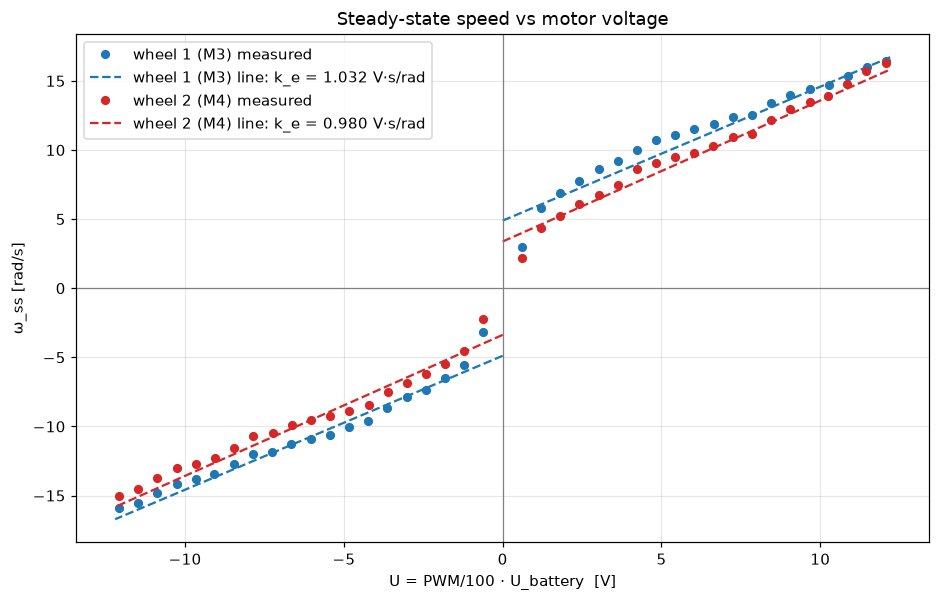

,k_e,U0,R2,k_e fwd,k_e rev,T_m
wheel 1 (M3),1.032,-5.044,0.996,1.017,1.047,0.134
wheel 2 (M4),0.980,-3.310,0.997,0.921,1.048,0.126


In [6]:
params = {}
for wheel in sorted(runs):
    d = fits[(fits.wheel == wheel) & fits.moving]
    U, W = d["U [V]"].values, d["ω_ss [rad/s]"].values
    A = np.column_stack([U, np.sign(U)])                     # W = a*U + c*sgn(U)
    (a, c), *_ = np.linalg.lstsq(A, W, rcond=None)
    r2 = 1 - np.sum((W - A @ [a, c]) ** 2) / np.sum((W - W.mean()) ** 2)
    k_fwd = 1 / np.polyfit(U[U > 0], W[U > 0], 1)[0]
    k_rev = 1 / np.polyfit(U[U < 0], W[U < 0], 1)[0]
    tm = d[(d["PWM %"].abs() >= 30)]["T_m [ms]"].median() / 1000
    params[wheel] = {"k_e": 1 / a, "U0": -c / a, "R2": r2, "k_e fwd": k_fwd, "k_e rev": k_rev, "T_m": tm}

fig, ax = plt.subplots(figsize=(10, 6))
for wheel, p in params.items():
    d = fits[fits.wheel == wheel]
    ax.plot(d["U [V]"], d["ω_ss [rad/s]"], "o", ms=5, color=COLOR[wheel], label=f"{WHEEL_NAME[wheel]} measured")
    for s in (1, -1):
        u = np.linspace(0, s * 12.2, 50)
        ax.plot(u, (u - s * p["U0"]) / p["k_e"], "--", color=COLOR[wheel],
                label=f"{WHEEL_NAME[wheel]} line: k_e = {p['k_e']:.3f} V·s/rad" if s == 1 else None)
ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
ax.set(title="Steady-state speed vs motor voltage", xlabel="U = PWM/100 · U_battery  [V]",
       ylabel="ω_ss [rad/s]")
ax.legend(); plt.show()

pd.DataFrame(params).T.rename(index=WHEEL_NAME).round(3)

**What this shows**
- Over most of the range the points follow a line, and the two wheels have similar `k_e` (≈ 1.03 and 0.98 V·s/rad).
- Near zero the line does **not** fit: at only 0.6 V the wheels already spin at 2–3 rad/s, about four to five times the ≈ 0.6 rad/s that the simple model ω = U/k_e predicts. The curve is concave (steep near zero, flatter at high voltage), so the best straight line needs a large negative offset `U₀`, and even then it over-predicts the lowest levels.
- The most likely reason: with a free-spinning wheel the TRIK's PWM driver does not act like an average voltage of `PWM · U_battery` at low duty, so `U` is not the true motor voltage there.

## 8. The time constant `T_m` across PWM levels

In [7]:
levels = [-100, -75, -50, -30, -10, 10, 30, 50, 75, 100]
tm = fits[fits["PWM %"].isin(levels)].pivot(index="PWM %", columns="wheel", values="T_m [ms]")
tm.columns = [f"T_m [ms] — {WHEEL_NAME[w]}" for w in tm.columns]
tm.index = tm.index.astype(str)
tm.loc["median over |PWM| ≥ 30 %"] = [params[w]["T_m"] * 1000 for w in sorted(params)]
tm.round(0)

,T_m [ms] — wheel 1 (M3),T_m [ms] — wheel 2 (M4)
PWM %,,
-100,53.0,44.0
-75,129.0,85.0
-50,239.0,196.0
-30,304.0,255.0
-10,445.0,356.0
10,439.0,319.0
30,338.0,257.0
50,235.0,90.0
75,137.0,113.0


The model assumes one constant `T_m`, but the measurement shows it **depends on the PWM level**: ≈ 300–450 ms at low PWM, falling to ≈ 45 ms at ±100 %. A few levels are far below their neighbours (e.g. wheel 2 at +50 %, compare the full table in section 6): in those runs the wheel started turning almost immediately, while normally it waits ≈ 30 ms before moving — the start-up of these small motors is not perfectly repeatable. For later weeks we use the **median over |PWM| ≥ 30 %** (the range the robot drives in), which is not affected by those few outliers.

## 9. Simulation check (`odeint`) against a measurement

Now the identified motor — **one** `k_e`, `U₀` and `T_m` per wheel, *not* the fit of this particular run — is simulated with `odeint` for the voltage of the +60 % step and compared with what the robot measured.

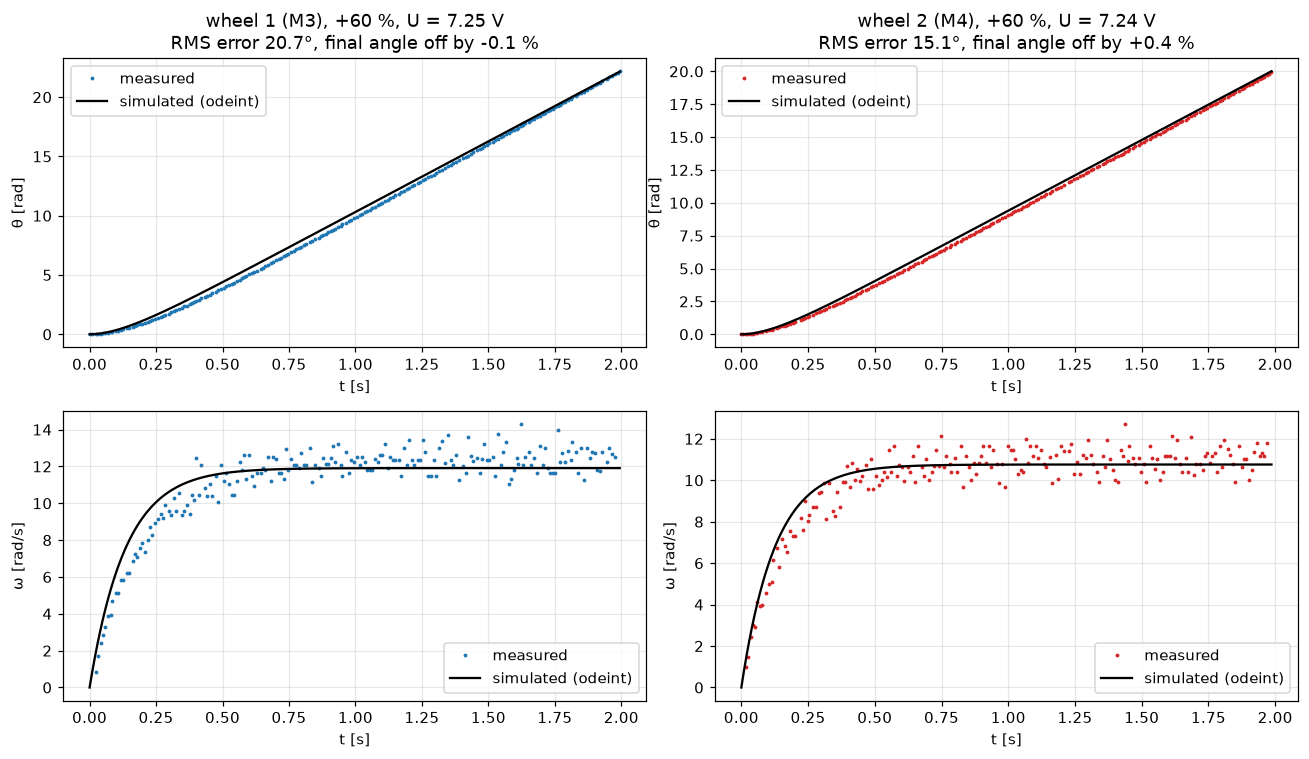

In [8]:
def finite_speed(t, theta, k=2):
    # speed from the angle: central difference over +-k samples (1 deg encoder resolution)
    w = np.full_like(theta, np.nan)
    w[k:-k] = (theta[2 * k:] - theta[:-2 * k]) / (t[2 * k:] - t[:-2 * k])
    return w

def simulate(p, U, t):
    u_eff = U - np.sign(U) * p["U0"]
    def motor(state, _t):
        w, th = state
        return [(u_eff / p["k_e"] - w) / p["T_m"], w]
    y = odeint(motor, [0.0, 0.0], t)
    return y[:, 1], y[:, 0]                             # theta, omega

PWM = 60
fig, axs = plt.subplots(2, 2, figsize=(12, 7))
for col, wheel in enumerate(sorted(runs)):
    h, t, theta = runs[wheel][PWM]
    U = PWM / 100 * float(h["battery_load_v"])
    tt = np.linspace(0, t[-1], 400)
    th_sim, w_sim = simulate(params[wheel], U, tt)
    rmse = np.degrees(np.sqrt(np.mean((theta - np.interp(t, tt, th_sim)) ** 2)))
    end = 100 * (th_sim[-1] - theta[-1]) / theta[-1]
    axs[0, col].plot(t, theta, ".", ms=3, color=COLOR[wheel], label="measured")
    axs[0, col].plot(tt, th_sim, "k-", label="simulated (odeint)")
    axs[0, col].set(title=f"{WHEEL_NAME[wheel]}, +{PWM} %, U = {U:.2f} V\nRMS error {rmse:.1f}°, final angle off by {end:+.1f} %",
                    xlabel="t [s]", ylabel="θ [rad]")
    axs[1, col].plot(t, finite_speed(t, theta), ".", ms=3, color=COLOR[wheel], label="measured")
    axs[1, col].plot(tt, w_sim, "k-", label="simulated (odeint)")
    axs[1, col].set(xlabel="t [s]", ylabel="ω [rad/s]")
    for a in axs[:, col]:
        a.legend()
plt.tight_layout(); plt.show()

The simulated wheel reaches the same speed and ends within half a percent of the measured angle after 2 s. The difference is at the start: the real motor accelerates a little more slowly than the model (it has a short start-up delay that a first-order model cannot represent), which is where most of the RMS error comes from.

## 10. How different are the two wheels? → odometry

If both motors get the same PWM but turn at different speeds, the robot drives in a curve instead of a straight line. For a track width $W$ (distance between the wheels), the heading changes by $\frac{2(\omega_1-\omega_2)}{W(\omega_1+\omega_2)}$ radians per metre travelled. $W = 0.194$ m is the value used in the course code.

In [9]:
W_TRACK = 0.194      # m, assumed
comp = []
for pwm in (-100, -50, 50, 100):
    w1 = fits[(fits.wheel == 1) & (fits["PWM %"] == pwm)]["ω_ss [rad/s]"].item()
    w2 = fits[(fits.wheel == 2) & (fits["PWM %"] == pwm)]["ω_ss [rad/s]"].item()
    comp.append({"PWM %": pwm, "ω wheel 1 (M3)": w1, "ω wheel 2 (M4)": w2,
                 "M4 slower by [%]": 100 * (abs(w1) - abs(w2)) / abs(w1),
                 "drift [° per metre]": abs(np.degrees(2 * (w1 - w2) / (W_TRACK * (w1 + w2))))})
pd.DataFrame(comp).set_index("PWM %").round(2)

,ω wheel 1 (M3),ω wheel 2 (M4),M4 slower by [%],drift [° per metre]
PWM %,,,,
-100,-15.90,-15.04,5.44,16.52
-50,-10.93,-9.52,12.92,40.78
50,11.53,9.78,15.19,48.55
100,16.42,16.32,0.60,1.77


M4 is clearly the weaker motor at medium speed (13–15 % slower at ±50 %), while at ±100 % the two are almost equal. With the same PWM on both motors the robot would curve towards the M4 side by roughly 40–50° per metre at half power.

Encoder odometry measures the *real* wheel rotation, so this difference does not make the odometry itself wrong — but the robot will not drive where it is told. That is why in Week 6–7 each wheel's speed should be controlled from its own encoder, instead of sending the same PWM to both motors.

## 11. Results and conclusions

In [10]:
summary = pd.DataFrame({
    WHEEL_NAME[w]: {"k_e [V·s/rad]": f"{p['k_e']:.3f}", "T_m [ms]": f"{p['T_m'] * 1000:.0f}",
                    "k_e forward / reverse": f"{p['k_e fwd']:.3f} / {p['k_e rev']:.3f}",
                    "line fit R²": f"{p['R2']:.3f}", "dead zone": "none"}
    for w, p in params.items()})
summary

,wheel 1 (M3),wheel 2 (M4)
k_e [V·s/rad],1.032,0.980
T_m [ms],134,126
k_e forward / reverse,1.017 / 1.047,0.921 / 1.048
line fit R²,0.996,0.997
dead zone,none,none


**Identified parameters (used in Weeks 6–7)**

| | `k_e` [V·s/rad] | `T_m` [ms] |
|---|---|---|
| Wheel 1 (M3) | 1.032 | 134 |
| Wheel 2 (M4) | 0.980 | 126 |

**Discussion**

The linear model fits the upper PWM range well but fails near zero. Neither motor has a dead zone: both wheels already turn at 2–3 rad/s at 5 % PWM (≈ 0.6 V), about four to five times the ≈ 0.6 rad/s that ω = U/k_e predicts, so ω_ss(U) is concave and the best straight line needs a negative offset (U₀ ≈ −5 V for M3, −3 V for M4). The most likely reason is that, with a free-spinning wheel, the PWM driver does not act like an average voltage of PWM · U_battery at low duty, so `U` is not the true motor voltage there. `T_m` is not constant either: it falls from 300–450 ms at low PWM to ≈ 45 ms at ±100 % (median 134 ms for M3 and 126 ms for M4 over |PWM| ≥ 30 %), and in four runs the start-up was clearly faster than at the neighbouring levels, so the identified model reproduces the speed reached but only roughly the acceleration (at +60 %: final angle within 0.4 %, RMS angle error 15–21°). The motors differ most at mid speed: M4 is 13–15 % slower than M3 at ±50 % PWM but only 0.6–5 % slower at ±100 %, and M4's forward and reverse k_e differ by 14 % (M3: 3 %). Encoder odometry measures the real wheel rotation, so this mismatch does not corrupt the dead-reckoning itself, but with equal PWM the robot will curve towards the M4 side by roughly 40–50° per metre at ±50 % PWM (for a 19.4 cm track), so next week the wheel speeds should be closed-loop per wheel, or at least feed-forward from the measured ω_ss(PWM) table rather than from a single k_e.

**Files in this folder**

| File | What it is |
|---|---|
| `motor_identification.qrs` / `.py` | the TRIK Studio program that collected the data |
| `motor_data/` | the 80 raw files exactly as the robot wrote them |
| `Motor_identification_Lab5.ipynb` | this notebook |
| `report.md`, `figures/`, `results/` | the same results as a written report |
| `motor_analysis.py` | the script that generated `report.md` |